# Import
- Import các thư viện
- Đọc dataset

In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
from PIL import Image
import os
import cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [28]:
EC = pd.read_csv('/kaggle/input/nh3h2-dataset2/Du lieu mix NH3H2.csv')

In [43]:
print(EC.shape)

(52535, 13)


In [44]:
EC

,feature 1,feature 2,feature 3,feature 4,feature 5,feature 6,feature 7,feature 8,feature 9,feature 10,Gas A,Gas B,Label
0,0.989,0.997,1.007,1.013,1.031,0.977,1.007,1.041,0.968,0.961,75.0,0.0,1
1,0.990,0.995,1.010,1.019,1.045,0.970,1.032,1.082,0.989,0.954,75.0,0.0,1
2,0.989,0.994,1.013,1.026,1.065,0.966,1.067,1.137,1.037,0.967,75.0,0.0,1
3,0.988,0.992,1.018,1.036,1.090,0.966,1.116,1.205,1.105,1.007,75.0,0.0,1
4,0.986,0.991,1.024,1.047,1.117,0.973,1.168,1.298,1.200,1.059,75.0,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
52530,1.114,0.986,0.961,0.983,1.025,1.148,1.067,1.303,1.437,1.461,0.0,350.0,35
52531,1.115,0.985,0.960,0.983,1.025,1.148,1.067,1.303,1.453,1.461,0.0,350.0,35
52532,1.115,0.985,0.960,0.983,1.025,1.148,1.070,1.303,1.463,1.461,0.0,350.0,35
52533,1.116,0.985,0.959,0.983,1.025,1.148,1.070,1.301,1.463,1.454,0.0,350.0,35


EC has 73 combinations
EM has 105 combinations

# Preprocessing
- Bỏ những dòng null/ bị thiếu
- Bỏ những dòng không có khí nào
- Chia tách các lần đo/ các instance bằng cách gán cột 'Label'
- Bỏ những lần đo ngắn hơn 64s

In [45]:
# Tìm null -> không có
missing_values = EC.isnull().any(axis=1)
print("Các dòng dữ liệu lỗi:")
print(EC[missing_values])

Các dòng dữ liệu lỗi:
Empty DataFrame
Columns: [feature 1, feature 2, feature 3, feature 4, feature 5, feature 6, feature 7, feature 8, feature 9, feature 10, Gas A, Gas B, Label]
Index: []


In [46]:
# Bỏ những dòng không có khí nào
EC3 = EC.loc[~((EC["Gas A"] == 0) & (EC["Gas B"] == 0))]
EC3 = EC3.reset_index(drop=True)

print(f"Previous EC shape: {EC.shape}")
print(f"After EC shape: {EC.shape}")
EC3.head()

Previous EC shape: (52535, 13)
After EC shape: (52535, 13)


,feature 1,feature 2,feature 3,feature 4,feature 5,feature 6,feature 7,feature 8,feature 9,feature 10,Gas A,Gas B,Label
0,0.989,0.997,1.007,1.013,1.031,0.977,1.007,1.041,0.968,0.961,75.0,0.0,1
1,0.990,0.995,1.010,1.019,1.045,0.970,1.032,1.082,0.989,0.954,75.0,0.0,1
2,0.989,0.994,1.013,1.026,1.065,0.966,1.067,1.137,1.037,0.967,75.0,0.0,1
3,0.988,0.992,1.018,1.036,1.090,0.966,1.116,1.205,1.105,1.007,75.0,0.0,1
4,0.986,0.991,1.024,1.047,1.117,0.973,1.168,1.298,1.200,1.059,75.0,0.0,1


# Split into 5 splits
- Tách data thành 5 phần nhỏ theo các lần đo (label)
- Chuẩn hóa (Normalization) từng phần bằng Min Max Scaler
- Các phần nhỏ không chứa label nào trùng nhau, có kich cỡ bằng nhau, được tách ngẫu nhiên

In [47]:
import random

numbers = list(range(1, len(EC3['Label'].unique())+1))
random.shuffle(numbers)

# Chia thành 5 list con xấp xỉ bằng nhau
k = 5
chunk_size = len(numbers) // k
remainder = len(numbers) % k

sublists = []
start = 0
for i in range(k):
    end = start + chunk_size + (1 if i < remainder else 0)
    sublists.append(numbers[start:end])
    start = end

# Kiểm tra độ dài từng list con
for i, sublist in enumerate(sublists):
    print(f"---List {i+1} ({len(sublist)} items): {sublist}")

---List 1 (7 items): [2, 10, 17, 35, 14, 23, 3]
---List 2 (7 items): [30, 25, 6, 16, 27, 32, 22]
---List 3 (7 items): [12, 26, 9, 20, 34, 28, 4]
---List 4 (7 items): [24, 5, 8, 7, 21, 19, 1]
---List 5 (7 items): [11, 33, 15, 13, 31, 29, 18]


In [48]:
# Tách dataframe thành 5 subdatasets tương ứng và Chuẩn hóa
X_col=[col for col in EC3.columns if 'feature' in col]
subdatasets = []
scaler = MinMaxScaler()

for i in range(k):
    subset = EC3[EC3['Label'].isin(sublists[i])].copy().reset_index(drop=True)
    # Normalization - chuẩn hóa trên từng tập subdata/ tập split nhỏ    
    subset[X_col] = pd.DataFrame(scaler.fit_transform(subset[X_col]), columns=X_col)

    subdatasets.append(subset)

# Kiểm tra kết quả
for i, subdf in enumerate(subdatasets):
    print(f"Subdataset {i+1}: {len(subdf)} rows")

Subdataset 1: 10507 rows
Subdataset 2: 10507 rows
Subdataset 3: 10507 rows
Subdataset 4: 10507 rows
Subdataset 5: 10507 rows


In [49]:
subdatasets[4]

,feature 1,feature 2,feature 3,feature 4,feature 5,feature 6,feature 7,feature 8,feature 9,feature 10,Gas A,Gas B,Label
0,0.007712,0.049133,0.093577,0.252468,0.159190,0.025964,0.032058,0.053018,0.034201,0.018179,75.0,75.0,11
1,0.010283,0.050578,0.099128,0.266573,0.170306,0.028205,0.035035,0.060128,0.038490,0.020782,75.0,75.0,11
2,0.011568,0.053468,0.103886,0.279267,0.181024,0.030633,0.038093,0.067495,0.042854,0.023444,75.0,75.0,11
3,0.012853,0.056358,0.109437,0.291961,0.190552,0.033061,0.041232,0.075057,0.047433,0.026285,75.0,75.0,11
4,0.014139,0.059249,0.114195,0.304654,0.199285,0.035614,0.044270,0.082708,0.051986,0.029278,75.0,75.0,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10502,0.179949,0.079480,0.289453,0.699577,0.638349,0.353589,0.528747,0.927072,0.936412,0.847126,87.5,262.5,33
10503,0.185090,0.083815,0.296590,0.708039,0.647082,0.365046,0.541465,0.932008,0.941040,0.855503,87.5,262.5,33
10504,0.188946,0.086705,0.304520,0.716502,0.656213,0.376378,0.553899,0.936485,0.945144,0.863126,87.5,262.5,33
10505,0.195373,0.089595,0.311657,0.724965,0.665740,0.387585,0.565909,0.940575,0.948803,0.870207,87.5,262.5,33


In [ ]:
import os
import shutil

folder = '/kaggle/working'

for filename in os.listdir(folder):
    file_path = os.path.join(folder, filename)
    try:
        if os.path.isfile(file_path) or os.path.islink(file_path):
            os.unlink(file_path)  # Xóa file hoặc symbolic link
        elif os.path.isdir(file_path):
            shutil.rmtree(file_path)  # Xóa thư mục con
    except Exception as e:
        print(f'Không thể xóa {file_path}. Lỗi: {e}')

# Augment 
**Thực hiện trên từng phần trong 5 phần:**
- Tăng cường bằng các bước nhảy lệch
- Chuyển sang cỡ ảnh 64x64 rồi lưu
- Mỗi lần đo/ instance/ group/ 1 ảnh gốc, sẽ được tăng cường thành 5 ảnh, lệch nhau step_size dòng

**Ví dụ:** 
- step_size = 10 => sẽ lấy bắt đầu từ index 0, 10, 20, 30, 40
- step_size = 20 => sẽ lấy bắt đầu từ index 0, 20, 40, 60, 80
- step_size = 25 => sẽ lấy bắt đầu từ index 0, 25, 50, 75, 100 (ảnh lấy từ 0 và 100 sẽ gần như trùng nhau)

**Mỗi ảnh sẽ gồm:**
- 64 cột (16 cột cảm biến x4),
- 64 dòng, mỗi dòng có Time(seconds) cách nhau 1 giây, tức cách nhau 100 dòng trong data gốc

In [50]:
# Setup
step_size = 3
X_col=[col for col in EC3.columns if 'feature' in col]
y_col=[col for col in EC3.columns if 'Gas' in col]

In [51]:
%%time
image_data = []

for i, subdata in enumerate(subdatasets):
    folder_name = f'augmented/split{i+1}'
    os.makedirs(folder_name, exist_ok=True)
    grouped_subdata = subdata.groupby('Label')
    
    for label, group in grouped_subdata:
        # Augment by 5 start_index
        for j, start in enumerate(range(0, 5*step_size, step_size)):
            # Get the data in one image
            image = group.iloc[start:(64*5+start):5][X_col]
            img_name = f"img_label{label}_aug{j}.png"

            # Normalize image to range (0, 255), convert to 64x64 size
            image = (image * 255).astype(np.uint8)
            image = np.repeat(image, 6, axis=1)  # shape: (64, 60)

            # Add 4 columns of zeros to make (64, 64)
            pad_width = ((0, 0), (0, 4))  # pad 4 columns to the right
            image = np.pad(image, pad_width, mode='constant', constant_values=0)

            # Save the image
            img_path = os.path.join(folder_name, img_name)
            Image.fromarray(image).save(img_path)
            
            # Save image information in csv
            row = np.append(group.head(1)[y_col].values[0],[img_name, i+1])
            image_data.append(row)

image_data_df = pd.DataFrame(image_data, columns=np.append(y_col,
                                          ['image_name',
                                          'split_number']))
image_data_df.to_csv('augmented/image_labels.csv', index=False)
image_data_df.groupby('split_number').count()

CPU times: user 391 ms, sys: 19.3 ms, total: 410 ms
Wall time: 413 ms


,Gas A,Gas B,image_name
split_number,,,
1,35,35,35
2,35,35,35
3,35,35,35
4,35,35,35
5,35,35,35


# Save augment data

In [52]:
import shutil

# Đường dẫn thư mục gốc chứa tất cả dữ liệu
root_dir = '/kaggle/working'

# Tên file zip đầu ra (không cần đuôi .zip, shutil sẽ thêm)
zip_name = '/kaggle/working/all_output'

# Tạo file nén .zip chứa toàn bộ nội dung trong thư mục output
shutil.make_archive(zip_name, 'zip', root_dir)

print(f"Đã tạo file nén: {zip_name}.zip")

Đã tạo file nén: /kaggle/working/all_output.zip


# Ví dụ đọc data và trường hợp lấy split số 1 làm tập test

In [3]:
# Đọc file csv chứa thông tin về ảnh (nồng độ, tên ảnh, split tương ứng)
folder = "augmented" 
#folder = "unaugment" 
df = pd.read_csv(f"/kaggle/input/data-53/{folder}/image_labels.csv")
df.head()

,Gas A,Gas B,image_name,split_number
0,67.5,7.5,img_label2_aug0.png,1
1,67.5,7.5,img_label2_aug1.png,1
2,67.5,7.5,img_label2_aug2.png,1
3,67.5,7.5,img_label2_aug3.png,1
4,67.5,7.5,img_label2_aug4.png,1


In [4]:
# Hàm đọc ảnh từ những split cho vào
# Trả về ảnh và nhãn tương ứng dưới dạng: ma trận [số ảnh, 64, 64, 1] và ma trận [số ảnh,2]
def read_img_from_splits(df, split_list):
    # Chỉ lấy các dòng thuộc list split đã chọn
    df_part = df[df['split_number'].isin(split_list)]
    images = []

    # Lặp qua từng hàng trong dataframe để đọc ảnh và lấy nhãn tương ứng 
    for index, row in df_part.iterrows():
        img_path = '/kaggle/input/data-53/'+folder + '/split' + str(row['split_number']) + '/' + str(row['image_name'])
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)  # Đọc ảnh xám
        img = np.array(img).astype('float32') / 255.0  # Chuẩn hóa dữ liệu ảnh
        images.append(img)

    # Chuyển đổi danh sách thành numpy arrays
    images = np.expand_dims(np.array(images), axis=-1)   # Thêm một chiều cho kênh ảnh
    
    return images, df_part[['Gas A', 'Gas B']]

In [5]:
# Xác định tập train và test sẽ gồm những split nào trong 5 split
# Chỉ cần điền những split trong tập test, tập train sẽ tự bao gồm những split còn lại
# VD: split_test = [3,5] thì split_train = [1,2,4]
split_test = [1]

split_train = [i for i in range(1,6) if i not in split_test] 
print("Những split sẽ thuộc tập train là: ", split_train)
print("Những split sẽ thuộc tập test là: ", split_test)

Những split sẽ thuộc tập train là:  [2, 3, 4, 5]
Những split sẽ thuộc tập test là:  [1]


In [6]:
%%time
# Sử dụng hàm đọc ảnh từ thư mục các split tương ứng
X_train, y_train1 = read_img_from_splits(df, split_train)
X_test, y_test1 = read_img_from_splits(df, split_test)
# Khởi tạo và áp dụng MinMaxScaler
scaler = MinMaxScaler()
y_train = scaler.fit_transform(y_train1)
y_test = scaler.fit_transform(y_test1)

print(f'X_train shape: {X_train.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_test shape: {y_test.shape}')

X_train shape: (140, 64, 64, 1)
y_train shape: (140, 2)
X_test shape: (35, 64, 64, 1)
y_test shape: (35, 2)
CPU times: user 80.4 ms, sys: 64 ms, total: 144 ms
Wall time: 1.69 s


In [7]:
import pandas as pd
import os
import seaborn as sns
import cv2
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Input, Flatten, Add, Dense, ReLU, Input, Activation 
from tensorflow.keras.layers import Dropout,AveragePooling2D,GlobalAveragePooling2D,BatchNormalization
from tensorflow.keras.regularizers import l2
from keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import MinMaxScaler
from sklearn import metrics
from sklearn.metrics import mean_absolute_error, r2_score

2025-07-27 13:30:54.170840: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753623054.380884      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753623054.447048      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [56]:
latent_dim = 256  # Kích thước vector ẩn

# Input
input_img = Input(shape=(64, 64, 1))

# Encoder
x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Flatten()(x)
encoded = layers.Dense(latent_dim, activation='relu')(x)

# Decoder
x = layers.Dense(8 * 8 * 128, activation='relu')(encoded)
x = layers.Reshape((8, 8, 128))(x)
x = layers.Conv2DTranspose(128, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x)
x = layers.Conv2DTranspose(64, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x)
x = layers.Conv2DTranspose(32, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x)
decoded = layers.Conv2DTranspose(1, (3, 3), activation='sigmoid', padding='same')(x)

In [57]:
# Tạo Autoencoder
autoencoder = models.Model(input_img, decoded)

# Tạo Encoder riêng biệt
encoder = models.Model(input_img, encoded)

# Compile
autoencoder.compile(optimizer='adam', loss='mse')

# Kiểm tra mô hình
autoencoder.summary()

Model: "functional_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 8192)           │     2,105,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_12             │ (None, 8, 8, 128)      │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_9 (UpSampling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_13             │ (None, 16, 16, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_10 (UpSampling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_14             │ (None, 32, 32, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_11 (UpSampling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_15             │ (None, 64, 64, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,535,553 (17.30 MB)

 Trainable params: 4,535,553 (17.30 MB)

 Non-trainable params: 0 (0.00 B)

In [58]:
# Giả sử có dữ liệu ảnh X_train (64x64x1)
autoencoder.fit(X_train, X_train, epochs=30, batch_size=32, validation_split=0.1)

Epoch 1/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 566ms/step - loss: 0.0923 - val_loss: 0.1066
Epoch 2/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 278ms/step - loss: 0.0772 - val_loss: 0.0583
Epoch 3/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 298ms/step - loss: 0.0641 - val_loss: 0.0816
Epoch 4/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 310ms/step - loss: 0.0399 - val_loss: 0.0240
Epoch 5/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 291ms/step - loss: 0.0217 - val_loss: 0.0229
Epoch 6/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 294ms/step - loss: 0.0164 - val_loss: 0.0189
Epoch 7/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 287ms/step - loss: 0.0147 - val_loss: 0.0178
Epoch 8/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 300ms/step - loss: 0.0116 - val_loss: 0.0109
Epoch 9/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 288ms/step - loss: 0.0102 - val_loss: 0.0122
Epoch 10/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 307ms/step - loss: 0.0089 - val_loss: 0.0107
Epoch 11/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 290ms/step - loss: 0.0084 - val_loss: 0.0102
Epoch 12/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 293ms/step - loss: 0.0078 - val_lo

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step


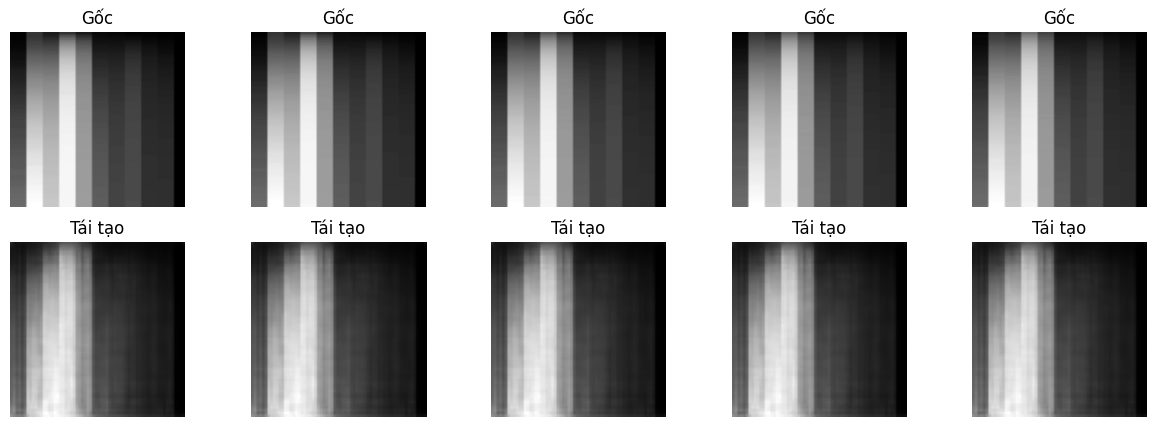

In [59]:
# Chọn một số ảnh từ tập test
num_images = 5
sample_images = X_test[:num_images]

# Dự đoán ảnh tái tạo
reconstructed_images = autoencoder.predict(sample_images)

# Vẽ ảnh gốc và ảnh tái tạo
fig, axes = plt.subplots(2, num_images, figsize=(15, 5))

for i in range(num_images):
    # Ảnh gốc
    axes[0, i].imshow(sample_images[i].squeeze(), cmap='gray')
    axes[0, i].axis('off')
    axes[0, i].set_title("Gốc")

    # Ảnh tái tạo
    axes[1, i].imshow(reconstructed_images[i].squeeze(), cmap='gray')
    axes[1, i].axis('off')
    axes[1, i].set_title("Tái tạo")

plt.show()


In [60]:
from sklearn.metrics import mean_squared_error

num_samples = min(len(X_test), len(reconstructed_images))

mse_scores = [
    mean_squared_error(X_test[i].flatten(), reconstructed_images[i].flatten())
    for i in range(num_samples)
]

print("MSE trung bình:", np.mean(mse_scores))

MSE trung bình: 0.0019801364


In [61]:
# Lấy đầu ra của encoder
X_train_encoded = encoder.predict(X_train)  # Dữ liệu ảnh chuyển thành vector đặc trưng
X_test_encoded = encoder.predict(X_test)
# Kiểm tra kích thước đặc trưng đã trích xuất
print(X_train_encoded.shape)  # Dự kiến: (số lượng mẫu, latent_dim)
print(X_test_encoded.shape)
print(y_train.shape)


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
(140, 256)
(35, 256)
(140, 2)


In [68]:
# Tìm các siêu tham số
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

# Tập hợp các giá trị siêu tham số cần tìm kiếm
param_grid = {
    'n_estimators': [200, 500, 1000],  
    'learning_rate': [0.005, 0.01, 0.02],  
    'max_depth': [3, 4, 5, 6],  
    'subsample': [0.8, 1],  
    'colsample_bytree': [0.7, 1]
}
# Khởi tạo mô hình XGBoost
xgb = XGBRegressor(objective='reg:squarederror', random_state=42)

# Khởi tạo GridSearchCV
grid_search = GridSearchCV(estimator=xgb, param_grid=param_grid, 
                           scoring='neg_mean_squared_error', cv=3, verbose=1, n_jobs=-1)

# Huấn luyện GridSearchCV trên tập train
grid_search.fit(X_train_encoded, y_train)

# In ra bộ tham số tốt nhất
print("Best parameters:", grid_search.best_params_)


Fitting 3 folds for each of 144 candidates, totalling 432 fits


KeyboardInterrupt: 

In [65]:
from xgboost import XGBRegressor
best_params = {
    'colsample_bytree': 0.7,
    'learning_rate': 0.02,
    'max_depth': 3,
    'n_estimators': 1000,
    'subsample': 0.8
}

# Khởi tạo mô hình với các tham số tối ưu
best_model = XGBRegressor(
    **best_params,                        # ← Giải nén dict thành các đối số
    objective='reg:squarederror',
    random_state=42
)

# Huấn luyện mô hình
best_model.fit(
    X_train_encoded, y_train,
    eval_set=[(X_train_encoded, y_train), (X_test_encoded, y_test)],
    eval_metric=["rmse", "mae"],
    verbose=False,
    early_stopping_rounds=100
)

/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.7, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.02, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=3, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1000, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [66]:
# MLP , XGBOOTS
from sklearn.metrics import mean_squared_error, mean_absolute_error

# best_model = grid_search.best_estimator_

# Dự đoán trên tập test
y_pred = best_model.predict(X_test_encoded)

y_pred_renormalized=scaler.inverse_transform(y_pred)
y_test_renormalized=scaler.inverse_transform(y_test)

In [67]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Output 1
mae_1 = mean_absolute_error(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
mse_1 = mean_squared_error(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
rmse_1 = np.sqrt(mse_1)
mean_y1 = np.mean(y_test_renormalized[:, 0])
nrmse_1 = rmse_1 / mean_y1

# Output 2
mae_2 = mean_absolute_error(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])
mse_2 = mean_squared_error(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])
rmse_2 = np.sqrt(mse_2)
mean_y2 = np.mean(y_test_renormalized[:, 1])
nrmse_2 = rmse_2 / mean_y2

# R2 Scores
r2_1 = r2_score(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
r2_2 = r2_score(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])

# In kết quả
# In kết quả
print(f"Output 1 - MAE: {mae_1:.4f}, MSE: {mse_1:.4f}, RMSE: {rmse_1:.4f}, NRMSE: {nrmse_1*100:.2f}%, R² Score: {r2_1:.4f}")
print(f"Output 2 - MAE: {mae_2:.4f}, MSE: {mse_2:.4f}, RMSE: {rmse_2:.4f}, NRMSE: {nrmse_2*100:.2f}%, R² Score: {r2_2:.4f}")

Output 1 - MAE: 18.9874, MSE: 607.7943, RMSE: 24.6535, NRMSE: 50.76%, R² Score: 0.6386
Output 2 - MAE: 60.9588, MSE: 6481.9537, RMSE: 80.5106, NRMSE: 47.56%, R² Score: 0.4720



(4)
AE_XGboots
Output 1 - MAE: 19.9366, MSE: 870.6554, RMSE: 29.5069, NRMSE: 39.82%, R² Score: 0.8588
Output 2 - MAE: 9.2119, MSE: 218.8315, RMSE: 14.7930, NRMSE: 18.62%, R² Score: 0.9532
MLP
Output 1 - MAE: 27.4293, MSE: 1163.5927, RMSE: 34.1115, NRMSE: 46.03%, R² Score: 0.8113
Output 2 - MAE: 23.3304, MSE: 765.8341, RMSE: 27.6737, NRMSE: 34.83%, R² Score: 0.8361
LSTM
Output 1 - MAE: 15.3762, MSE: 500.8760, RMSE: 22.3803, NRMSE: 30.20%, R² Score: 0.9188
Output 2 - MAE: 11.5412, MSE: 294.9567, RMSE: 17.1743, NRMSE: 21.61%, R² Score: 0.9369
(5) XGboot
Output 1 - MAE: 36.4608, MSE: 2001.5426, RMSE: 44.7386, NRMSE: 28.73%, R² Score: 0.8355
Output 2 - MAE: 17.4116, MSE: 438.2775, RMSE: 20.9351, NRMSE: 22.20%, R² Score: 0.9363
2 Xgboot:
Output 1 - MAE: 54.3385, MSE: 4345.2760, RMSE: 65.9187, NRMSE: 39.86%, R² Score: 0.6392
Output 2 - MAE: 16.6263, MSE: 746.3230, RMSE: 27.3189, NRMSE: 27.34%, R² Score: 0.9156
(3) Xgboot:
Output 1 - MAE: 15.2959, MSE: 305.0515, RMSE: 17.4657, NRMSE: 35.96%, R² Score: 0.8186
Output 2 - MAE: 58.3380, MSE: 6007.9589, RMSE: 77.5110, NRMSE: 45.79%, R² Score: 0.5106

Output 1 - MAE: 51.3632, MSE: 3939.6266, RMSE: 62.7664, NRMSE: 37.96%, R² Score: 0.6729
Output 2 - MAE: 15.3918, MSE: 627.1020, RMSE: 25.0420, NRMSE: 25.06%, R² Score: 0.9291
(1) Xgboot:
Output 1 - MAE: 29.5668, MSE: 1014.4758, RMSE: 31.8508, NRMSE: 33.97%, R² Score: 0.8691
Output 2 - MAE: 19.5088, MSE: 735.3596, RMSE: 27.1175, NRMSE: 29.49%, R² Score: 0.9434

In [21]:
import shutil

# Nén toàn bộ thư mục /kaggle/working thành file working.zip
shutil.make_archive('/kaggle/working/working', 'zip', '/kaggle/working')

'/kaggle/working/working.zip'

In [17]:
import matplotlib.pyplot as plt
import numpy as np

def plot_groundtruth_vs_prediction(y_true, y_pred, gas_name="Gas Concentration"):
    # Lấy 101 phần tử đầu tiên
    y_true = y_true[:245]
    y_pred = y_pred[:245]
    x = np.arange(245)

    # Tính độ lệch
    delta = y_pred - y_true

    # Tăng DPI khi hiển thị
    plt.figure(figsize=(10, 5), dpi=150)

    # Vẽ Groundtruth
    plt.plot(x, y_true, label=f"Groundtruth {gas_name}", color='blue', linewidth=2.5)

    # Vẽ Prediction
    plt.plot(x, y_pred, label=f"Prediction {gas_name}", color='red', linestyle='--', linewidth=2.5)

    # Vẽ độ lệch Δ
    plt.plot(x, delta, label="Δ (Prediction - Groundtruth)", color='green', linewidth=3)

    # Nhãn và định dạng
    plt.xlabel("Sample Index", fontsize=18)
    plt.ylabel("Concentration (scaled)", fontsize=18)
    plt.legend(fontsize=16)
    plt.tick_params(axis='both', which='major', labelsize=16)
    #plt.grid(True, linestyle='--', alpha=0.5)
    # ✅ Thêm lưới
    plt.grid(True, linestyle='--', alpha=0.5)
    # Bố cục và lưu file độ phân giải cao
    plt.tight_layout()
    plt.savefig("prediction_vs_groundtruth_with_delta.png", dpi=600)
    plt.show()

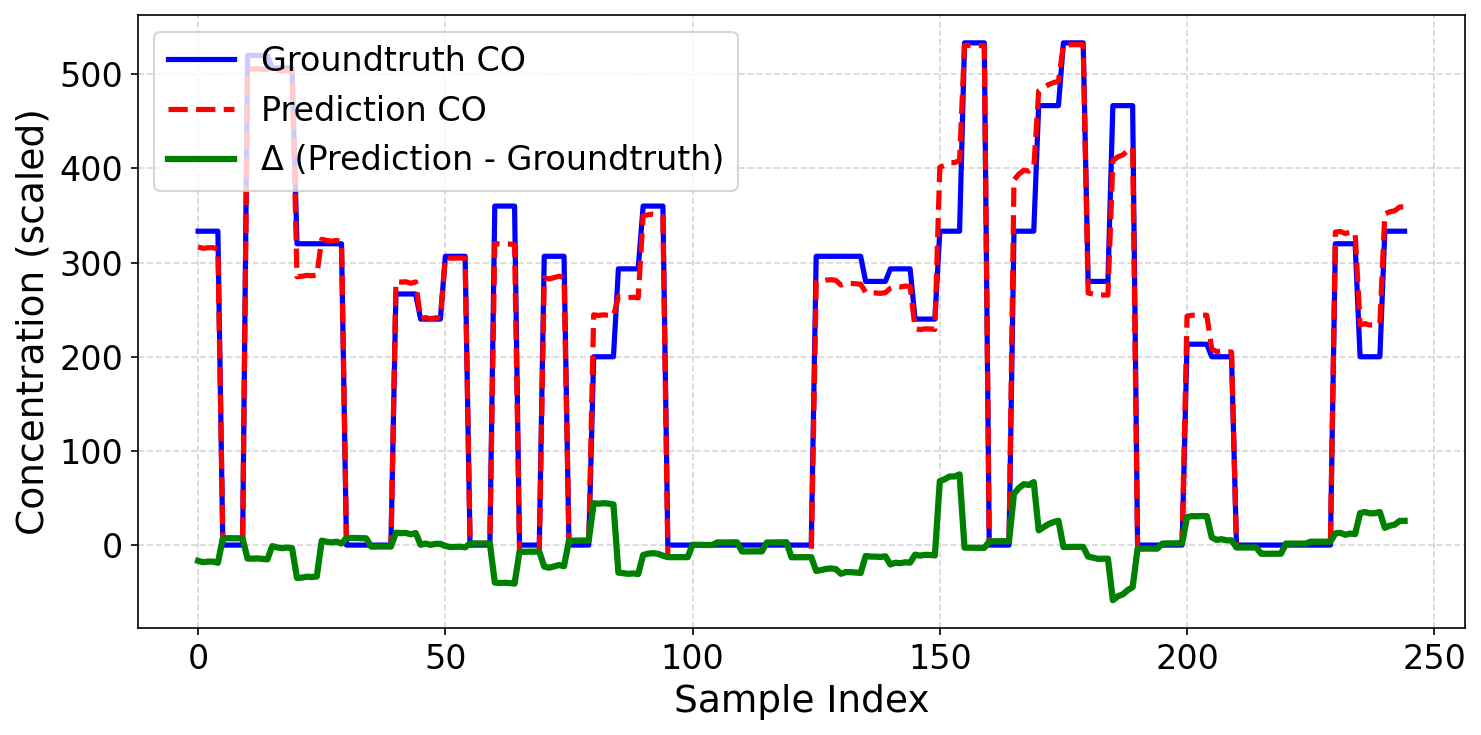

In [18]:
# Ví dụ cho việc vẽ lại biểu đồ sau khi inverse transform
plot_groundtruth_vs_prediction(y_test_renormalized[:, 0], y_pred_renormalized[:, 0], gas_name="CO")


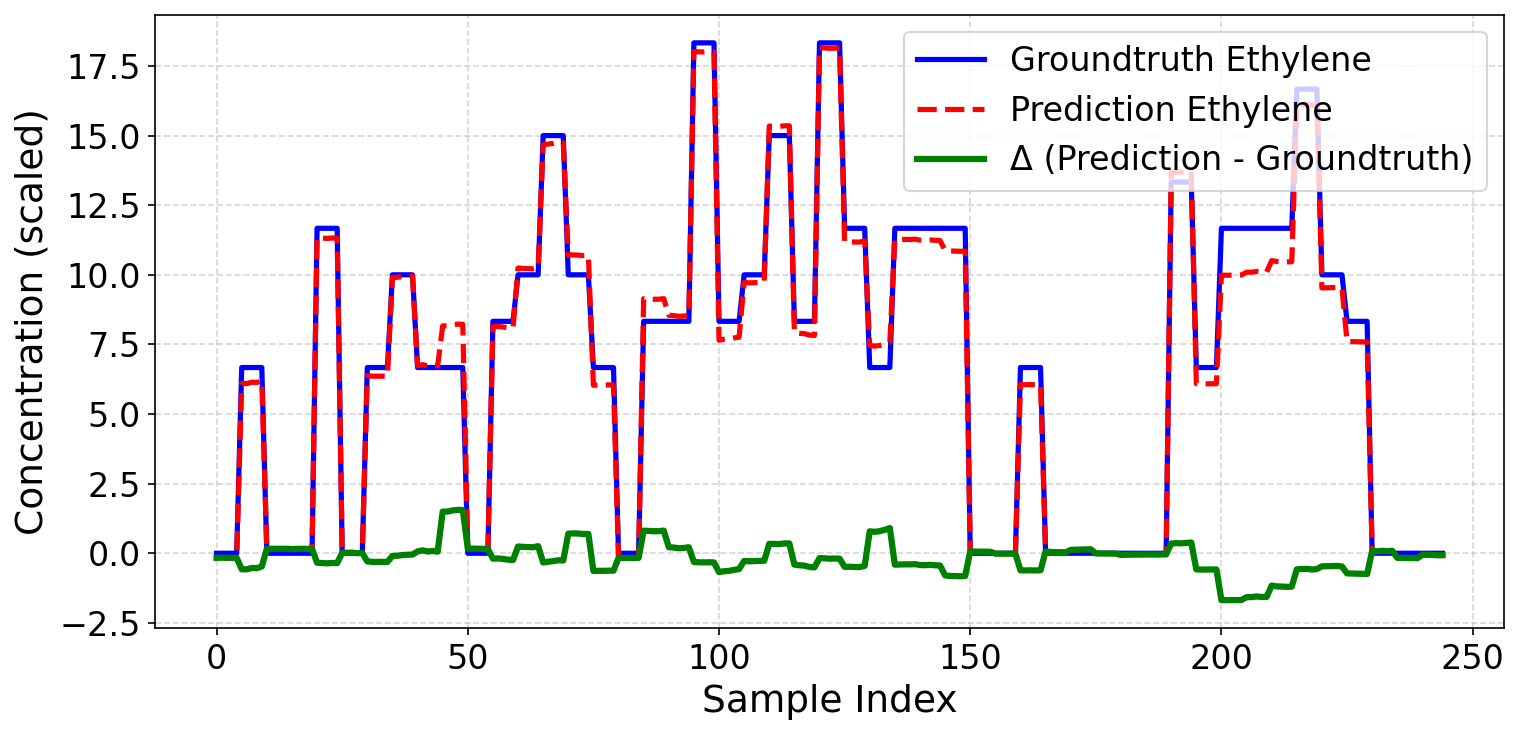

In [19]:
plot_groundtruth_vs_prediction(y_test_renormalized[:, 1], y_pred_renormalized[:, 1], gas_name="Ethylene")

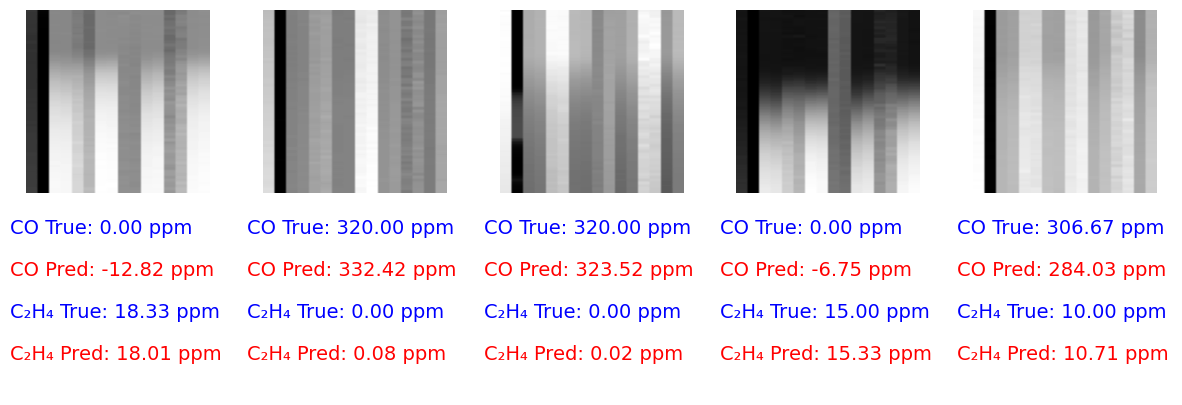

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Chọn 5 mẫu ngẫu nhiên từ tập kiểm tra
num_samples = 5
random_indices = np.random.choice(X_test.shape[0], num_samples, replace=False)

plt.figure(figsize=(15, 5))  # Giảm chiều cao figure

for i, idx in enumerate(random_indices):
    img = X_test[idx].reshape(64, 64)
    true_co2 = y_test_renormalized[idx, 0]
    true_ethylene = y_test_renormalized[idx, 1]
    pred_co2 = y_pred_renormalized[idx, 0]
    pred_ethylene = y_pred_renormalized[idx, 1]

    # Hiển thị ảnh
    plt.subplot(2, 5, i + 1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    #plt.title(f"Sample {idx+1}", fontsize=11)

    # Hiển thị thông tin khí
    plt.subplot(2, 5, i + 6)
    plt.axis('off')
    plt.text(0.0, 0.88, f"CO True: {true_co2:.2f} ppm", color="blue", fontsize=14)
    plt.text(0.0, 0.65, f"CO Pred: {pred_co2:.2f} ppm", color="red", fontsize=14)
    plt.text(0.0, 0.42, f"C₂H₄ True: {true_ethylene:.2f} ppm", color="blue", fontsize=14)
    plt.text(0.0, 0.19, f"C₂H₄ Pred: {pred_ethylene:.2f} ppm", color="red", fontsize=14)

# Tinh chỉnh layout: giảm khoảng cách giữa các hàng và cột
plt.subplots_adjust(wspace=0.1, hspace=0.1)
plt.savefig("reconstruction_compact.png", dpi=600, bbox_inches='tight')
plt.show()

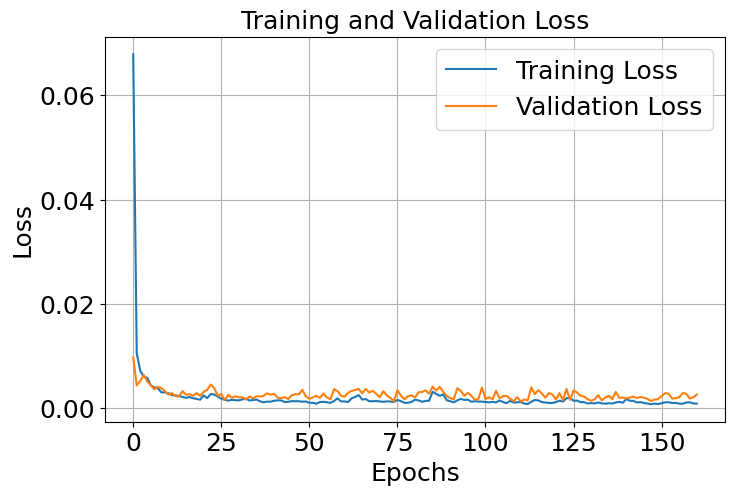

In [51]:
# CHUAN LOSS với font size 18
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs', fontsize=18)
plt.ylabel('Loss', fontsize=18)
plt.title('Training and Validation Loss', fontsize=18)
plt.legend(fontsize=18)
plt.grid(True)

# Tăng font của các chỉ số trục
plt.tick_params(axis='both', which='major', labelsize=18)

plt.show()

In [159]:
# XGBoot
results = best_model.evals_result()

# 🎨 Vẽ RMSE
plt.figure(figsize=(8, 5))
plt.plot(results['validation_0']['rmse'], label='Training RMSE')
plt.plot(results['validation_1']['rmse'], label='Validation RMSE')

# Thêm nhãn và legend với font lớn
plt.xlabel("Epochs", fontsize=18)
plt.ylabel("RMSE", fontsize=18)
#plt.title("RMSE Learning Curve", fontsize=18)
plt.legend(fontsize=18)

# Tăng kích thước chữ số trên trục
plt.tick_params(axis='both', which='major', labelsize=18)

# Căn chỉnh bố cục và lưu ảnh
plt.tight_layout()
plt.savefig("reconstruction_highres.png", dpi=600)
plt.show()

AttributeError: 'Sequential' object has no attribute 'evals_result'

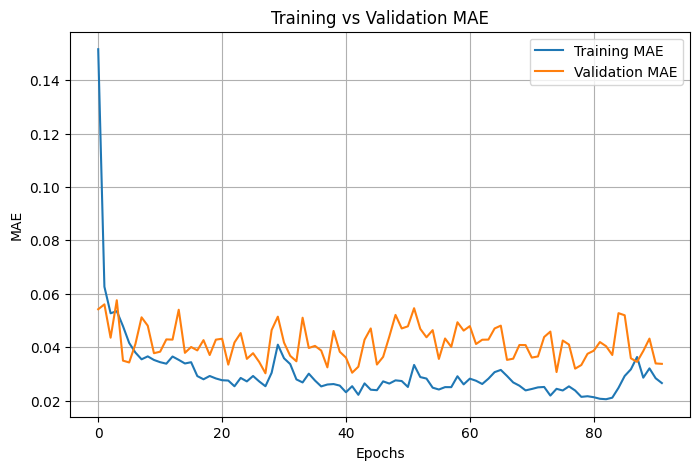

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.title('Training vs Validation MAE')
plt.legend()
plt.grid(True)
plt.show()

In [163]:
# 🎨 Vẽ MAE # XGBoot
plt.figure(figsize=(8, 5))
plt.plot(results['validation_0']['mae'], label='Training MAE')
plt.plot(results['validation_1']['mae'], label='Validation MAE')

# Tăng kích thước chữ
plt.xlabel("Epochs", fontsize=18)
plt.ylabel("MAE", fontsize=18)
#plt.title("MAE Learning Curve", fontsize=18)
plt.legend(fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=18)

# Căn chỉnh bố cục và lưu ảnh chất lượng cao
plt.tight_layout()
plt.savefig("reconstruction_highres.png", dpi=600)
plt.show()


NameError: name 'results' is not defined

<Figure size 800x500 with 0 Axes>

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


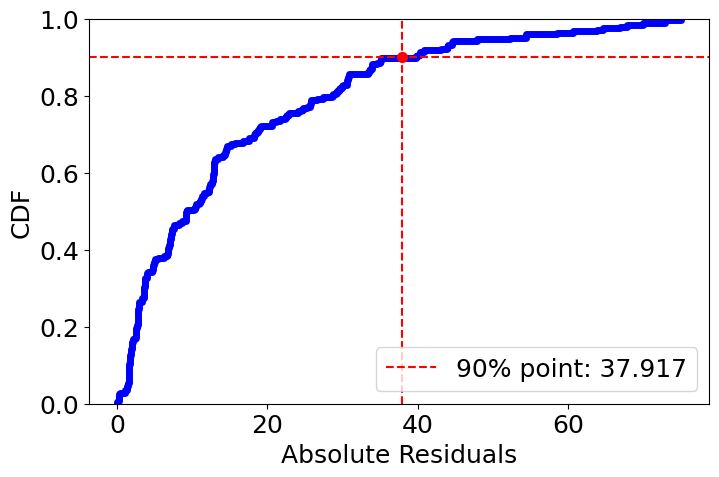

In [22]:
# Compute absolute residuals
abs_residuals_gas1 = np.abs(y_test_renormalized[:, 0] - y_pred_renormalized[:, 0])
abs_residuals_gas2 = np.abs(y_test_renormalized[:, 1] - y_pred_renormalized[:, 1])

# Compute 90th percentile values
x90_gas1 = np.percentile(abs_residuals_gas1, 90)
### 🎨 Plot CDF cho Gas 1 (CO)
plt.figure(figsize=(8, 5))
sns.ecdfplot(abs_residuals_gas1, color='blue', linewidth=5)
plt.axvline(x=x90_gas1, color='red', linestyle='--', label=f"90% point: {x90_gas1:.3f}")
plt.axhline(y=0.9, color='red', linestyle='--')
plt.scatter([x90_gas1], [0.9], color='red', s=50, zorder=10)
#plt.title("CDF of Absolute Residuals for CO", fontsize=16)
plt.xlabel("Absolute Residuals", fontsize=18)
plt.ylabel("CDF", fontsize=18)
plt.legend(fontsize=18)
plt.tick_params(axis='both', labelsize=18)
plt.savefig("reconstruction_highres.png", dpi=600)

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


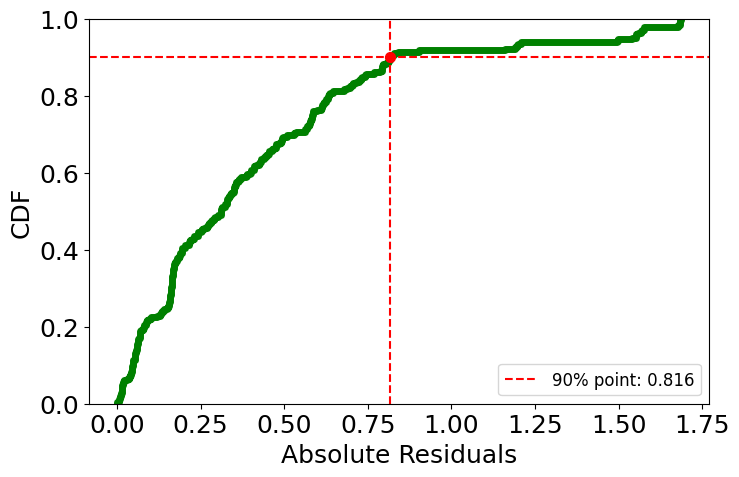

In [23]:
x90_gas2 = np.quantile(abs_residuals_gas2, 0.9)
### 🎨 Plot CDF cho Gas 2 (Ethylene)
plt.figure(figsize=(8, 5))
sns.ecdfplot(abs_residuals_gas2, color='green', linewidth=5)
plt.axvline(x=x90_gas2, color='red', linestyle='--', label=f"90% point: {x90_gas2:.3f}")
plt.axhline(y=0.9, color='red', linestyle='--')
plt.scatter([x90_gas2], [0.9], color='red', s=50, zorder=18)
#plt.title("CDF of Absolute Residuals for Ethylene", fontsize=18)
plt.xlabel("Absolute Residuals", fontsize=18)
plt.ylabel("CDF", fontsize=18)
plt.legend(fontsize=12)
plt.tick_params(axis='both', labelsize=18)
plt.savefig("reconstruction_highres.png", dpi=600)

In [72]:
#=======================MLP===============
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Khởi tạo mô hình MLP
best_model = Sequential()
best_model.add(Dense(128, activation='relu', input_shape=(X_train_encoded.shape[1],)))
best_model.add(Dropout(0.3))  # tương đương subsample/colsample_bytree để tránh overfitting
best_model.add(Dense(64, activation='relu'))
best_model.add(Dropout(0.3))
best_model.add(Dense(2))  # Sửa thành 2 neurons để dự đoán 2 biến đầu ra

# Compile mô hình
best_model.compile(
    optimizer=Adam(learning_rate=0.02),  # dùng learning_rate từ best_params
    loss='mse',
    metrics=['mae']
)

# Early stopping tương đương với n_estimators
early_stop = EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)

# Huấn luyện mô hình
history = best_model.fit(
    X_train_encoded, y_train,
    validation_data=(X_test_encoded, y_test),
    epochs=1000,         # tương đương n_estimators
    batch_size=32,
    verbose=1,
    callbacks=[early_stop]
)

Epoch 1/1000


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 160ms/step - loss: 1.4767 - mae: 0.8767 - val_loss: 0.2175 - val_mae: 0.3426
Epoch 2/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1392 - mae: 0.2757 - val_loss: 0.0761 - val_mae: 0.2268
Epoch 3/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1063 - mae: 0.2429 - val_loss: 0.1083 - val_mae: 0.2424
Epoch 4/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0627 - mae: 0.1895 - val_loss: 0.0900 - val_mae: 0.2079
Epoch 5/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0702 - mae: 0.2033 - val_loss: 0.0944 - val_mae: 0.2188
Epoch 6/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0496 - mae: 0.1657 - val_loss: 0.0892 - val_mae: 0.2177
Epoch 7/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0474 - mae: 0.1585 - val_loss: 0.0772 - val_mae: 0.1947
Epoch 8/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0510 - mae: 0.1708 - val_loss: 0.0967 - val_mae: 0.2135
Epoch 9/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0420 - mae: 0.1

In [62]:
# LSTM====================CHUAN MOI
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np

# Reshape dữ liệu thành (samples, timesteps=1, features)
X_train_lstm = np.reshape(X_train_encoded, (X_train_encoded.shape[0], 1, X_train_encoded.shape[1]))
X_test_lstm = np.reshape(X_test_encoded, (X_test_encoded.shape[0], 1, X_test_encoded.shape[1]))

# Khởi tạo mô hình LSTM
best_model = Sequential()
best_model.add(LSTM(128, activation='tanh', return_sequences=True, input_shape=(1, X_train_encoded.shape[1])))
best_model.add(Dropout(0.2))
best_model.add(LSTM(64, activation='tanh', return_sequences=False))
best_model.add(Dropout(0.2))
best_model.add(Dense(32, activation='relu'))
best_model.add(Dense(2))

# Compile mô hình
best_model.compile(
    optimizer=Adam(learning_rate=0.02),  # từ best_params 0.02
    loss='mse',
    metrics=['mae']
    
)

# Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)

# Huấn luyện mô hình
history = best_model.fit(
    X_train_lstm, y_train,
    validation_data=(X_test_lstm, y_test),
    epochs=1000,
    batch_size=32,
    verbose=1,
    callbacks=[early_stop]
)

Epoch 1/1000


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 184ms/step - loss: 0.1285 - mae: 0.2661 - val_loss: 0.0809 - val_mae: 0.2203
Epoch 2/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0362 - mae: 0.1409 - val_loss: 0.0929 - val_mae: 0.2347
Epoch 3/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0221 - mae: 0.1151 - val_loss: 0.0664 - val_mae: 0.1928
Epoch 4/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0184 - mae: 0.1013 - val_loss: 0.0644 - val_mae: 0.1955
Epoch 5/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0137 - mae: 0.0896 - val_loss: 0.0556 - val_mae: 0.1856
Epoch 6/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0096 - mae: 0.0723 - val_loss: 0.0535 - val_mae: 0.1799
Epoch 7/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0124 - mae: 0.0827 - val_loss: 0.0531 - val_mae: 0.1778
Epoch 8/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0116 - mae: 0.0786 - val_loss: 0.0595 - val_mae: 0.1810
Epoch 9/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0091 - mae: 0.0

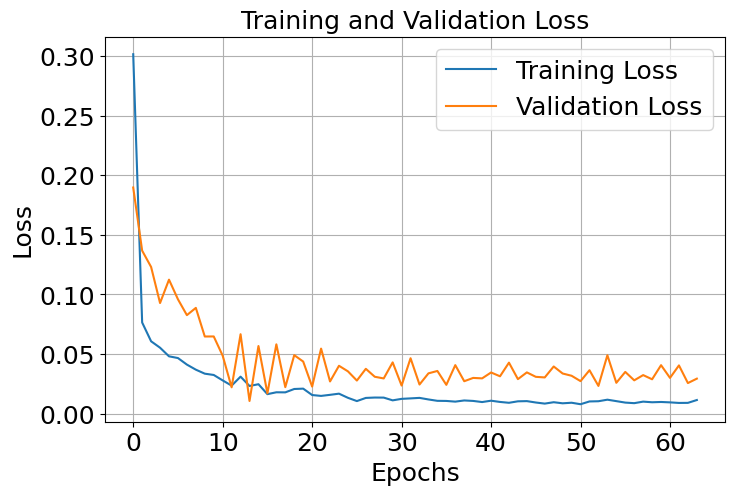

In [218]:
# CHUAN LOSS với font size 18
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs', fontsize=18)
plt.ylabel('Loss', fontsize=18)
plt.title('Training and Validation Loss', fontsize=18)
plt.legend(fontsize=18)
plt.grid(True)

# Tăng font của các chỉ số trục
plt.tick_params(axis='both', which='major', labelsize=18)

plt.show()

In [63]:
# Chuyển đổi dữ liệu test sang dạng 3D cho LSTM
X_test_lstm = np.reshape(X_test_encoded, (X_test_encoded.shape[0], 1, X_test_encoded.shape[1]))

# Dự đoán
y_pred = best_model.predict(X_test_lstm)

# Giải chuẩn hóa kết quả nếu cần
y_pred_renormalized = scaler.inverse_transform(y_pred)
y_test_renormalized = scaler.inverse_transform(y_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 485ms/step


In [64]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Output 1
mae_1 = mean_absolute_error(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
mse_1 = mean_squared_error(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
rmse_1 = np.sqrt(mse_1)
mean_y1 = np.mean(y_test_renormalized[:, 0])
nrmse_1 = rmse_1 / mean_y1

# Output 2
mae_2 = mean_absolute_error(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])
mse_2 = mean_squared_error(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])
rmse_2 = np.sqrt(mse_2)
mean_y2 = np.mean(y_test_renormalized[:, 1])
nrmse_2 = rmse_2 / mean_y2

# R2 Scores
r2_1 = r2_score(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
r2_2 = r2_score(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])

# In kết quả
# In kết quả
print(f"Output 1 - MAE: {mae_1:.4f}, MSE: {mse_1:.4f}, RMSE: {rmse_1:.4f}, NRMSE: {nrmse_1*100:.2f}%, R² Score: {r2_1:.4f}")
print(f"Output 2 - MAE: {mae_2:.4f}, MSE: {mse_2:.4f}, RMSE: {rmse_2:.4f}, NRMSE: {nrmse_2*100:.2f}%, R² Score: {r2_2:.4f}")

Output 1 - MAE: 9.6729, MSE: 129.4052, RMSE: 11.3756, NRMSE: 23.42%, R² Score: 0.9231
Output 2 - MAE: 51.3077, MSE: 4428.6965, RMSE: 66.5485, NRMSE: 39.31%, R² Score: 0.6392


(4) LSTM
Output 1 - MAE: 15.3762, MSE: 500.8760, RMSE: 22.3803, NRMSE: 30.20%, R² Score: 0.9188
Output 2 - MAE: 11.5412, MSE: 294.9567, RMSE: 17.1743, NRMSE: 21.61%, R² Score: 0.9369
(3)
Output 1 - MAE: 48.9227, MSE: 3218.9152, RMSE: 56.7355, NRMSE: 34.31%, R² Score: 0.7327
Output 2 - MAE: 25.2062, MSE: 763.4227, RMSE: 27.6301, NRMSE: 27.65%, R² Score: 0.9137

Output 1 - MAE: 4.1589, MSE: 28.7689, RMSE: 5.3637, NRMSE: 11.04%, R² Score: 0.9829
Output 2 - MAE: 51.4108, MSE: 4308.6498, RMSE: 65.6403, NRMSE: 38.77%, R² Score: 0.6490

Output 1 - MAE: 10.0483, MSE: 158.8600, RMSE: 12.6040, NRMSE: 25.95%, R² Score: 0.9055
Output 2 - MAE: 48.5733, MSE: 4154.0480, RMSE: 64.4519, NRMSE: 38.07%, R² Score: 0.6616
(2)
Output 1 - MAE: 35.7119, MSE: 2201.2273, RMSE: 46.9172, NRMSE: 28.37%, R² Score: 0.8172
Output 2 - MAE: 19.9000, MSE: 802.3683, RMSE: 28.3261, NRMSE: 28.35%, R² Score: 0.9093

(5)
Output 1 - MAE: 21.3474, MSE: 768.6220, RMSE: 27.7240, NRMSE: 17.80%, R² Score: 0.9368
Output 2 - MAE: 12.1440, MSE: 223.2124, RMSE: 14.9403, NRMSE: 15.85%, R² Score: 0.9676
(2)
Output 1 - MAE: 26.7549, MSE: 873.8830, RMSE: 29.5615, NRMSE: 17.88%, R² Score: 0.9274
Output 2 - MAE: 23.9610, MSE: 862.0748, RMSE: 29.3611, NRMSE: 29.38%, R² Score: 0.9025
(1)
Output 1 - MAE: 17.9442, MSE: 446.0726, RMSE: 21.1204, NRMSE: 22.53%, R² Score: 0.9424
Output 2 - MAE: 18.1754, MSE: 471.6054, RMSE: 21.7165, NRMSE: 23.61%, R² Score: 0.9637


In [84]:
# CNN cơ bản
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.models import Model

# Đầu vào ảnh 64x64x1
inputs = Input(shape=(64, 64, 1))

# Convolutional layers
x = Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
x = MaxPooling2D(pool_size=(2, 2))(x)

x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = MaxPooling2D(pool_size=(2, 2))(x)

x = Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = MaxPooling2D(pool_size=(2, 2))(x)

# Flatten và fully-connected layers
x = Flatten()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)  # để tránh overfitting

# Nhánh đầu ra cho CO concentration
output1 = Dense(64, activation='relu')(x)
output1 = Dense(32, activation='relu')(output1)
output1 = Dense(1, activation='linear', name="Gas1_concentration")(output1)

# Nhánh đầu ra cho Ethylene concentration
output2 = Dense(64, activation='relu')(x)
output2 = Dense(32, activation='relu')(output2)
output2 = Dense(1, activation='linear', name="Gas2_concentration")(output2)

# Tạo mô hình CNN thường với 2 đầu ra
model = Model(inputs=inputs, outputs=[output1, output2])

# Compile mô hình
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss={'Gas1_concentration': 'mse', 'Gas2_concentration': 'mse'},
    metrics={'Gas1_concentration': 'mae', 'Gas2_concentration': 'mae'}
)

# Tóm tắt mô hình
model.summary()

Model: "functional_29"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10      │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 64, 64,    │        320 │ input_layer_10[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_13    │ (None, 32, 32,    │          0 │ conv2d_19[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 32, 32,    │     18,496 │ max_pooling2d_13… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_14    │ (None, 16, 16,    │          0 │ conv2d_20[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 16, 16,    │     73,856 │ max_pooling2d_14… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_15    │ (None, 8, 8, 128) │          0 │ conv2d_21[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_5 (Flatten) │ (None, 8192)      │          0 │ max_pooling2d_15… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_28 (Dense)    │ (None, 128)       │  1,048,704 │ flatten_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 128)       │          0 │ dense_28[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_29 (Dense)    │ (None, 64)        │      8,256 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_31 (Dense)    │ (None, 64)        │      8,256 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_30 (Dense)    │ (None, 32)        │      2,080 │ dense_29[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_32 (Dense)    │ (None, 32)        │      2,080 │ dense_31[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas1_concentration  │ (None, 1)         │         33 │ dense_30[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas2_concentration  │ (None, 1)         │         33 │ dense_32[0][0]    │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,162,114 (4.43 MB)

 Trainable params: 1,162,114 (4.43 MB)

 Non-trainable params: 0 (0.00 B)

In [83]:
# Đầu vào Resnet8
inputs = Input(shape=(64, 64, 1))

# Khối Convolutional (mô phỏng ResNet-8)
x = Conv2D(64, (3, 3), activation='relu')(inputs)
x = MaxPooling2D(pool_size=(3, 3))(x)
x = Conv2D(64, (3, 3), activation='relu')(x)
x = Conv2D(64, (3, 3), activation='relu')(x)
x = Conv2D(64, (3, 3), activation='relu')(x)
x = Conv2D(128, (3, 3), activation='relu')(x)
x = Conv2D(128, (3, 3), activation='relu')(x)
x = Conv2D(128, (3, 3), activation='relu')(x)
x = Flatten()(x)

# Nhánh đầu ra cho CO concentration
output1 = Dense(64, activation='relu')(x)
output1 = Dense(32, activation='relu')(output1)
output1 = Dense(1, activation='linear',name="Gas1_concentration")(output1)

# Nhánh đầu ra cho Ethylene concentration
output2 = Dense(64, activation='relu')(x)
output2 = Dense(32, activation='relu')(output2)
output2 = Dense(1, activation='linear',name="Gas2_concentration")(output2)

# Tạo mô hình với hai đầu ra
model = Model(inputs=inputs, outputs=[output1, output2])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss={'Gas1_concentration': 'mse', 'Gas2_concentration': 'mse'},
              metrics={'Gas1_concentration': 'mae', 'Gas2_concentration': 'mae'})

model.summary()

Model: "functional_28"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 62, 62,    │        640 │ input_layer_9[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_12    │ (None, 20, 20,    │          0 │ conv2d_12[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 18, 18,    │     36,928 │ max_pooling2d_12… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 16, 16,    │     36,928 │ conv2d_13[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 14, 14,    │     36,928 │ conv2d_14[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 12, 12,    │     73,856 │ conv2d_15[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 10, 10,    │    147,584 │ conv2d_16[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 8, 8, 128) │    147,584 │ conv2d_17[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_4 (Flatten) │ (None, 8192)      │          0 │ conv2d_18[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_24 (Dense)    │ (None, 64)        │    524,352 │ flatten_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_26 (Dense)    │ (None, 64)        │    524,352 │ flatten_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_25 (Dense)    │ (None, 32)        │      2,080 │ dense_24[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_27 (Dense)    │ (None, 32)        │      2,080 │ dense_26[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas1_concentration  │ (None, 1)         │         33 │ dense_25[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas2_concentration  │ (None, 1)         │         33 │ dense_27[0][0]    │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,533,378 (5.85 MB)

 Trainable params: 1,533,378 (5.85 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
#RNN
import tensorflow as tf
from tensorflow.keras.layers import Input, Reshape, SimpleRNN, Dense, Dropout
from tensorflow.keras.models import Model

# Đầu vào ảnh 64x64x1 (coi như chuỗi 64 bước, mỗi bước 64 đặc trưng)
inputs = Input(shape=(64, 64, 1))  # (batch_size, time_steps, features, channels)

# Bỏ chiều kênh cuối cùng (1), reshape thành (batch_size, time_steps=64, features=64)
x = Reshape((64, 64))(inputs)  # (batch_size, time_steps, features)

# RNN layers (thay LSTM bằng SimpleRNN)
x = SimpleRNN(128, return_sequences=True, activation='tanh')(x)
x = SimpleRNN(64, activation='tanh')(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)

# Nhánh đầu ra cho CO concentration
output1 = Dense(64, activation='relu')(x)
output1 = Dense(32, activation='relu')(output1)
output1 = Dense(1, activation='linear', name="Gas1_concentration")(output1)

# Nhánh đầu ra cho Ethylene concentration
output2 = Dense(64, activation='relu')(x)
output2 = Dense(32, activation='relu')(output2)
output2 = Dense(1, activation='linear', name="Gas2_concentration")(output2)

# Tạo mô hình RNN hai đầu ra
model = Model(inputs=inputs, outputs=[output1, output2])

# Compile mô hình
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss={'Gas1_concentration': 'mse', 'Gas2_concentration': 'mse'},
    metrics={'Gas1_concentration': 'mae', 'Gas2_concentration': 'mae'}
)

# Hiển thị kiến trúc mô hình
model.summary()

2025-07-27 13:31:11.070618: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 64, 64)    │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn          │ (None, 64, 128)   │     24,704 │ reshape[0][0]     │
│ (SimpleRNN)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_1        │ (None, 64)        │     12,352 │ simple_rnn[0][0]  │
│ (SimpleRNN)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │      8,320 │ simple_rnn_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      2,080 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 32)        │      2,080 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas1_concentration  │ (None, 1)         │         33 │ dense_2[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas2_concentration  │ (None, 1)         │         33 │ dense_4[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 66,114 (258.26 KB)

 Trainable params: 66,114 (258.26 KB)

 Non-trainable params: 0 (0.00 B)

In [78]:
# LSTM
import tensorflow as tf
from tensorflow.keras.layers import Input, Reshape, LSTM, Dense, Dropout
from tensorflow.keras.models import Model

# Đầu vào ảnh 64x64x1 (coi như chuỗi 64 bước, mỗi bước 64 đặc trưng)
inputs = Input(shape=(64, 64, 1))  # (batch_size, time_steps, features, channels)

# Bỏ chiều kênh cuối cùng (1), reshape thành (batch_size, time_steps=64, features=64)
x = Reshape((64, 64))(inputs)  # (batch_size, time_steps, features)

# RNN layers
x = LSTM(128, return_sequences=True)(x)   # LSTM đầu tiên
x = LSTM(64)(x)                            # LSTM thứ hai
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)

# Nhánh đầu ra cho CO concentration
output1 = Dense(64, activation='relu')(x)
output1 = Dense(32, activation='relu')(output1)
output1 = Dense(1, activation='linear', name="Gas1_concentration")(output1)

# Nhánh đầu ra cho Ethylene concentration
output2 = Dense(64, activation='relu')(x)
output2 = Dense(32, activation='relu')(output2)
output2 = Dense(1, activation='linear', name="Gas2_concentration")(output2)

# Tạo mô hình RNN hai đầu ra
model = Model(inputs=inputs, outputs=[output1, output2])

# Compile mô hình
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss={'Gas1_concentration': 'mse', 'Gas2_concentration': 'mse'},
    metrics={'Gas1_concentration': 'mae', 'Gas2_concentration': 'mae'}
)

# Hiển thị kiến trúc mô hình
model.summary()

Model: "functional_27"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_5 (Reshape) │ (None, 64, 64)    │          0 │ input_layer_8[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_8 (LSTM)       │ (None, 64, 128)   │     98,816 │ reshape_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_9 (LSTM)       │ (None, 64)        │     49,408 │ lstm_8[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_19 (Dense)    │ (None, 128)       │      8,320 │ lstm_9[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 128)       │          0 │ dense_19[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_20 (Dense)    │ (None, 64)        │      8,256 │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_22 (Dense)    │ (None, 64)        │      8,256 │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_21 (Dense)    │ (None, 32)        │      2,080 │ dense_20[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_23 (Dense)    │ (None, 32)        │      2,080 │ dense_22[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas1_concentration  │ (None, 1)         │         33 │ dense_21[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas2_concentration  │ (None, 1)         │         33 │ dense_23[0][0]    │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 177,282 (692.51 KB)

 Trainable params: 177,282 (692.51 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Huấn luyện mô hình với hai đầu ra
history = model.fit(
    X_train, 
    {'Gas1_concentration': y_train[:, 0], 'Gas2_concentration': y_train[:, 1]},
    epochs= 100, 
    batch_size=32, 
    validation_data=(X_test, {'Gas1_concentration': y_test[:, 0], 'Gas2_concentration': y_test[:, 1]})
)


Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 252ms/step - Gas1_concentration_loss: 0.1851 - Gas1_concentration_mae: 0.3406 - Gas2_concentration_loss: 0.1549 - Gas2_concentration_mae: 0.3163 - loss: 0.3479 - val_Gas1_concentration_loss: 0.0955 - val_Gas1_concentration_mae: 0.3069 - val_Gas2_concentration_loss: 0.1681 - val_Gas2_concentration_mae: 0.3898 - val_loss: 0.3224
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - Gas1_concentration_loss: 0.1010 - Gas1_concentration_mae: 0.2543 - Gas2_concentration_loss: 0.1077 - Gas2_concentration_mae: 0.2668 - loss: 0.2116 - val_Gas1_concentration_loss: 0.0695 - val_Gas1_concentration_mae: 0.2735 - val_Gas2_concentration_loss: 0.1493 - val_Gas2_concentration_mae: 0.1298 - val_loss: 0.1545
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - Gas1_concentration_loss: 0.0616 - Gas1_concentration_mae: 0.1952 - Gas2_concentration_loss: 0.0745 - Gas2_concentration_mae: 0.2025 - loss: 0.1328 - val_Gas1_concentration_loss: 0.0927 - val_Gas1_concentration_m

In [10]:
from sklearn.metrics import mean_absolute_error, r2_score

# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

# Tách dự đoán cho từng khí
y_pred_gas1 = y_pred[0] # Dự đoán nồng độ khí 1
y_pred_gas2 = y_pred[1] # Dự đoán nồng độ khí 2


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 374ms/step


In [11]:
# Inverse transform cho giá trị ground truth và dự đoán
# Ghép lại dự đoán thành mảng 2 chiều để inverse transform
y_pred_combined = np.column_stack((y_pred_gas1, y_pred_gas2))

# Inverse transform cho ground truth và dự đoán
y_true_rescaled = scaler.inverse_transform(y_test)  # Ground truth
y_pred_rescaled = scaler.inverse_transform(y_pred_combined)  # Dự đoán đã ghép

# Tách lại sau khi rescale để dùng cho các bước tiếp theo (nếu cần)
y_pred_gas1_rescaled = y_pred_rescaled[:, 0]
y_pred_gas2_rescaled = y_pred_rescaled[:, 1]
y_true_gas1_rescaled = y_true_rescaled[:, 0]
y_true_gas2_rescaled = y_true_rescaled[:, 1]

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# CO gas
mae_1 = mean_absolute_error(y_true_gas1_rescaled, y_pred_gas1_rescaled)
mse_1 = mean_squared_error(y_true_gas1_rescaled, y_pred_gas1_rescaled)
rmse_1 = np.sqrt(mse_1)
nrmse_1 = rmse_1 / (np.max(y_true_gas1_rescaled) - np.min(y_true_gas1_rescaled))
r2_1 = r2_score(y_true_gas1_rescaled, y_pred_gas1_rescaled)

# Ethylene gas
mae_2 = mean_absolute_error(y_true_gas2_rescaled, y_pred_gas2_rescaled)
mse_2 = mean_squared_error(y_true_gas2_rescaled, y_pred_gas2_rescaled)
rmse_2 = np.sqrt(mse_2)
nrmse_2 = rmse_2 / (np.max(y_true_gas2_rescaled) - np.min(y_true_gas2_rescaled))
r2_2 = r2_score(y_true_gas2_rescaled, y_pred_gas2_rescaled)

# In kết quả
print(f"CO gas       - MAE: {mae_1:.4f}, MSE: {mse_1:.4f}, RMSE: {rmse_1:.4f}, NRMSE: {nrmse_1*100:.2f}%, R² Score: {r2_1:.4f}")
print(f"Ethylene gas - MAE: {mae_2:.4f}, MSE: {mse_2:.4f}, RMSE: {rmse_2:.4f}, NRMSE: {nrmse_2*100:.2f}%, R² Score: {r2_2:.4f}")

CO gas       - MAE: 39.9238, MSE: 2395.0817, RMSE: 48.9396, NRMSE: 18.13%, R² Score: 0.6910
Ethylene gas - MAE: 30.7934, MSE: 2290.2791, RMSE: 47.8569, NRMSE: 13.97%, R² Score: 0.8238


CNN:
CO gas       - MAE: 46.2468, MSE: 5296.3782, RMSE: 72.7762, NRMSE: 13.65%, R² Score: 0.8346
Ethylene gas - MAE: 2.1780, MSE: 9.2690, RMSE: 3.0445, NRMSE: 16.61%, R² Score: 0.7038
RNN
CO gas       - MAE: 23.6308, MSE: 1291.1493, RMSE: 35.9326, NRMSE: 6.74%, R² Score: 0.9597
Ethylene gas - MAE: 1.5184, MSE: 4.9149, RMSE: 2.2169, NRMSE: 12.09%, R² Score: 0.8429